In [1]:
import torch
from PIL import Image
import open_clip

from torch import nn
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch.nn.functional as F
from torchvision import transforms

from stable_worldmodel.wm.loss import SIGReg

/pfs/proj/nobackup/fs/projnb10/hpc2n2025-254/DINO-WMTraining/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
"""import zipfile

with zipfile.ZipFile("RSICD_images.zip", "r") as zip_ref:
    zip_ref.extractall("RSICD_images")"""

'import zipfile\n\nwith zipfile.ZipFile("RSICD_images.zip", "r") as zip_ref:\n    zip_ref.extractall("RSICD_images")'

In [3]:
corruption_transform = transforms.Compose([
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=9, sigma=(1.0, 4.0))
    ], p=0.5),
    transforms.RandomApply([
        transforms.Grayscale(num_output_channels=3)
    ], p=0.3),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.6, contrast=0.6,
            saturation=0.6, hue=0.1
        )
    ], p=0.5),
])

In [4]:
class LabeledRSICD(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        item = self.records[idx]

        image = Image.open(
            IMAGE_DIR / item["filename"]
        ).convert("RGB")

        image = train_transform(image)

        # Select one of the five captions randomly.
        captions = [
            sentence["raw"]
            for sentence in item["sentences"]
        ]
        caption = random.choice(captions)

        return image, caption

class UnlabeledRSICD(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(
            self.paths[idx]
        ).convert("RGB")

        # Two independent augmented views.
        view1 = train_transform(image)
        corrupted_image = corruption_transform(image)
        view2 = train_transform(corrupted_image)

        return view1, view2

In [5]:
BATCH_SIZE = 32

In [6]:
from pathlib import Path
import json
from torch.utils.data import Dataset, DataLoader, random_split
import random

ROOT = Path(".")
JSON_PATH = ROOT / "dataset_rsicd.json"
IMAGE_DIR = ROOT / "RSICD_images" / "RSICD_images"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

records = data["images"]

# Split A: filenames only. Never use their captions.
unlabeled_paths = [
    IMAGE_DIR / item["filename"]
    for item in records
    if item["split"] == "train"
]

# Split B: labeled image-caption pairs.
labeled_records = [
    item for item in records
    if item["split"] == "val"
]

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model, train_transform, val_transform = (
    open_clip.create_model_and_transforms(
        "ViT-B-32",
        pretrained="laion2b_s34b_b79k",
    )
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")
model = model.to(device)

In [8]:
generator = torch.Generator().manual_seed(42)

n_val = max(1, int(0.2 * len(labeled_records)))
n_train = len(labeled_records) - n_val

train_records, val_records = random_split(
    labeled_records,
    [n_train, n_val],
    generator=generator,
)

train_records = [labeled_records[i] for i in train_records.indices]
val_records = [labeled_records[i] for i in val_records.indices]

labeled_loader = DataLoader(
    LabeledRSICD(train_records),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

val_labeled_loader = DataLoader(
    LabeledRSICD(val_records),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

unlabeled_loader = DataLoader(
    UnlabeledRSICD(unlabeled_paths),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

In [9]:
batch = next(iter(labeled_loader))
batch[0].shape

/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

torch.Size([32, 3, 224, 224])

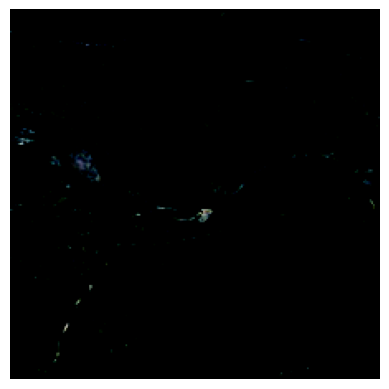

In [10]:
import matplotlib.pyplot as plt

image = batch[0][2].permute(1, 2, 0).cpu().numpy()

plt.imshow(image)
plt.axis('off')
plt.show()

In [11]:
"""image = batch[1][2].permute(1, 2, 0).cpu().numpy()

plt.imshow(image)
plt.axis('off')
plt.show()"""

list(batch[1])

['many buildings are in an industrial area .',
 'overall assumes the circular stadium .',
 'light green plants are in two sides of a curved river .',
 'many green trees and a pond are in a park .',
 'the middle is the parking lot and parked cars .',
 'many buildings and green trees are in a school .',
 'some buildings and many green trees are near a viaduct .',
 'it is a large piece of bareland .',
 'port is surrounded by a sea .',
 'the square into a symmetric distribution .',
 'many buildings and some green trees are in a school .',
 'several buildings and a piece of green meadow are around a circle square .',
 'a piece of bareland and many buildings are in two sides of a large building .',
 'the school is divided into several areas .',
 'the bareland with brown land in the middle .',
 'many green trees are in a forest .',
 'there are white and gray land cover on the part of the red land, a few green, pot-holed ground .',
 'many buildings with parking lots are in two sides of a railw

In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.LayerNorm(dim),
            nn.ReLU(),
            nn.Linear(dim, dim),
            nn.LayerNorm(dim)
        )

    def forward(self, x):
        return F.relu(x + self.block(x))


class CLIPJepa(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.enc = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.LayerNorm(1024),
            nn.ReLU(),

            ResidualBlock(1024),
            ResidualBlock(1024),
            ResidualBlock(1024),

            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, output_dim)
        )

        self.pred = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.LayerNorm(1024),
            nn.ReLU(),

            ResidualBlock(1024),
            ResidualBlock(1024),
            ResidualBlock(1024),

            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, output_dim)
        )

        self.sigreg = SIGReg()

    def encode(self, x):
        return self.enc(x)

    def forward(self, x, x_):
        target = self.enc(x)
        predicted = self.pred(x_)

        loss = (
            F.mse_loss(predicted, target)
            + self.sigreg(target)
        )

        return loss

In [23]:
learn_rate = 1e-4
weight_decay = 1e-5
clip_head = CLIPJepa(512, 512).to(device=device)
optimizer = torch.optim.Adam(clip_head.parameters(), lr=learn_rate, weight_decay=weight_decay)

In [24]:
def train(labeled_loader, unlabeled_loader, model, clip_head, optimizer, tokenizer):
    model.train()
    clip_head.train()
    for epoch in range(200):
        total_loss = 0.0
        for labeled_batch, unlabeled_batch in zip(labeled_loader, unlabeled_loader):
            # Labeled batch
            labeled_images, labeled_texts = labeled_batch
        
            # Unlabeled batch 
            unlabeled_images_t, unlabeled_images_c = unlabeled_batch
    
            optimizer.zero_grad()
        
            clip_t = model.encode_image(unlabeled_images_t.to(device=device))
            clip_c = model.encode_image(unlabeled_images_c.to(device=device))
    
            image_features = model.encode_image(labeled_images.to(device=device))
            text_features = model.encode_text(tokenizer(labeled_texts).to(device=device))
            image_features = F.normalize(image_features.float(), dim=-1)
            text_features = F.normalize(text_features.float(), dim=-1)
            text_probs = (100.0 * clip_head.encode(image_features) @ text_features.T).softmax(dim=-1)
            labels = torch.arange(text_probs.size(0), device=text_probs.device)
            
            loss = clip_head(clip_t, clip_c) + (F.cross_entropy(text_probs, labels) + F.cross_entropy(text_probs.T, labels)) / 2.0
            loss.backward()
            optimizer.step()
            total_loss += loss.detach().item()
    
        print(total_loss)

In [25]:
train(labeled_loader, unlabeled_loader, model, clip_head, optimizer, tokenizer)

/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

395.9967956542969


/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

244.10958290100098


/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

...

127.01728963851929


/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

127.65583181381226


/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

126.2358169555664


In [26]:
import torch
import torch.nn.functional as F

def evaluate(labeled_loader, model, clip_head, tokenizer, device=device):
    model.eval()
    clip_head.eval()

    total_loss = 0.0
    total_i2t_correct = 0
    total_t2i_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, texts in labeled_loader:
            images = images.to(device)
            texts = texts #.to(device)

            image_features = model.encode_image(images)
            text_features = model.encode_text(tokenizer(texts).to(device))

            image_features = F.normalize(image_features.float(), dim=-1)
            text_features = F.normalize(text_features.float(), dim=-1)

            # Match the image projection used during training
            image_features = clip_head.encode(image_features)

            logits = 100.0 * image_features @ text_features.T
            labels = torch.arange(logits.size(0), device=logits.device)

            loss_i2t = F.cross_entropy(logits, labels)
            loss_t2i = F.cross_entropy(logits.T, labels)
            loss = loss_i2t + loss_t2i

            total_loss += loss.item() * images.size(0)

            # Retrieval accuracy within each batch
            total_i2t_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            total_t2i_correct += (
                logits.T.argmax(dim=1) == labels
            ).sum().item()

            total_samples += images.size(0)

    if total_samples == 0:
        return {}

    results = {
            "loss": total_loss / total_samples,
            "image_to_text_accuracy": total_i2t_correct / total_samples,
            "text_to_image_accuracy": total_t2i_correct / total_samples,
        }
    
    print(f"Validation loss: {results['loss']:.4f}")
    print(f"Image-to-text accuracy: {results['image_to_text_accuracy']:.4f}")
    print(f"Text-to-image accuracy: {results['text_to_image_accuracy']:.4f}")

    return results

In [40]:
# Evaluation prompt configuration (counterpart to configs/prompts/course.yaml)
EVAL_TEMPLATES = ["A satellite image of {}.", "an aerial image of {}.", "a remote sensing image of {}.", "a satellite photo of a {}.", "an aerial photograph of a {}.", "a top-down satellite view of {}."]

In [41]:
# FULL_RSICD_EVALUATION
from pathlib import Path
import re
from PIL import Image
import torch
import torch.nn.functional as F

# Deterministic validation preprocessing; use all five captions for retrieval.
EVAL_BATCH_SIZE = 32
assert all(len(record["sentences"]) == 5 for record in val_records), "Expected five captions per RSICD image."
caption_texts = [sentence["raw"] for record in val_records for sentence in record["sentences"]]
record_index_by_filename = {record["filename"]: i for i, record in enumerate(val_records)}

@torch.no_grad()
def encode_eval_texts(texts, batch_size=256):
    features = []
    for start in range(0, len(texts), batch_size):
        tokens = tokenizer(texts[start:start + batch_size]).to(device)
        feats = model.encode_text(tokens).float()
        features.append(F.normalize(feats, dim=-1).cpu())
    return torch.cat(features)

@torch.no_grad()
def encode_eval_image_views(records, batch_size=EVAL_BATCH_SIZE):
    # D4 group: four quarter-turn rotations and their horizontal reflections.
    views = [[] for _ in range(8)]
    for start in range(0, len(records), batch_size):
        batch_records = records[start:start + batch_size]
        images = torch.stack([
            val_transform(Image.open(IMAGE_DIR / item["filename"]).convert("RGB"))
            for item in batch_records
        ]).to(device)
        for group_index in range(8):
            view = torch.rot90(images, group_index % 4, dims=(2, 3))
            if group_index >= 4:
                view = view.flip(3)
            image_features = model.encode_image(view).float()
            image_features = F.normalize(clip_head.encode(image_features), dim=-1)
            views[group_index].append(image_features.cpu())
    return torch.stack([torch.cat(group_features) for group_features in views], dim=1)

@torch.no_grad()
def retrieval_metrics(image_features, text_features, ks=(1, 5, 10)):
    # Five consecutive captions in text_features belong to each image.
    n_images = image_features.shape[0]
    similarities = image_features @ text_features.T
    caption_owner = torch.arange(n_images).repeat_interleave(5)
    image_ids = torch.arange(n_images)

    i2t_order = similarities.argsort(dim=1, descending=True)
    i2t_rank = (caption_owner[i2t_order] == image_ids[:, None]).float().argmax(dim=1)
    t2i_order = similarities.T.argsort(dim=1, descending=True)
    t2i_rank = (t2i_order == caption_owner[:, None]).float().argmax(dim=1)

    results = {}
    recall_values = []
    for k in ks:
        i2t = (i2t_rank < k).float().mean().item()
        t2i = (t2i_rank < k).float().mean().item()
        results[f"i2t_R@{k}"] = i2t
        results[f"t2i_R@{k}"] = t2i
        recall_values.extend([i2t, t2i])

    # Multi-positive symmetric contrastive loss: all five captions are correct.
    logits = 100.0 * similarities
    positives = caption_owner[None, :] == image_ids[:, None]
    i2t_loss = (
        torch.logsumexp(logits, dim=1)
        - torch.logsumexp(logits.masked_fill(~positives, -torch.inf), dim=1)
    ).mean()
    t2i_loss = (
        torch.logsumexp(logits.T, dim=1)
        - torch.logsumexp(logits.T.masked_fill(~positives.T, -torch.inf), dim=1)
    ).mean()
    results["mR"] = sum(recall_values) / len(recall_values)
    results["loss"] = (i2t_loss + t2i_loss).item()
    results["image_to_text_accuracy"] = results["i2t_R@1"]
    results["text_to_image_accuracy"] = results["t2i_R@1"]
    return results

model.eval()
clip_head.eval()
image_features_d4 = encode_eval_image_views(val_records)
caption_features = encode_eval_texts(caption_texts)
base_image_features = image_features_d4[:, 0]

# Retrieval metrics over the entire validation subset (rather than within batches).
full_eval_metrics = retrieval_metrics(base_image_features, caption_features)

# Load class labels from the standard RSICD category text files, as in the linked project.
# Each txt file is a class; its lines list image filenames belonging to that class.
CLASS_DIR = ROOT / "txtclasses_rsicd"
filename_to_class = {}
if CLASS_DIR.is_dir():
    class_files = sorted(CLASS_DIR.glob("*.txt"))
    class_names = [re.sub(r"(?<!^)(?=[A-Z])", " ", f.stem).replace("_", " ").lower()
                   for f in class_files]
    for class_index, class_file in enumerate(class_files):
        for line in class_file.read_text(encoding="utf-8", errors="replace").splitlines():
            filename = Path(line.strip()).name
            if filename:
                filename_to_class[filename] = class_index
    labeled_eval_records = [r for r in val_records if r["filename"] in filename_to_class]
else:
    class_names = []
    labeled_eval_records = []

if labeled_eval_records:
    eval_labels = torch.tensor(
        [filename_to_class[r["filename"]] for r in labeled_eval_records], dtype=torch.long
    )
    # Match the subset used for classification to its encoded image features.
    selected_indices = [record_index_by_filename[r["filename"]] for r in labeled_eval_records]
    selected_images = base_image_features[selected_indices]
    def class_embeddings(class_names, templates):
        prompt_texts = [template.format(name) for name in class_names for template in templates]
        features = encode_eval_texts(prompt_texts)
        features = features.reshape(len(class_names), len(templates), -1).mean(1)
        return F.normalize(features, dim=-1)

    prompt_features = class_embeddings(class_names, EVAL_TEMPLATES)
    full_eval_metrics["zs_acc"] = (selected_images @ prompt_features.T).argmax(1).eq(eval_labels).float().mean().item()
    present_classes = eval_labels.unique()
    full_eval_metrics["zs_mean_per_class_acc"] = torch.stack([
        (selected_images[eval_labels == class_id] @ prompt_features.T).argmax(1)
        .eq(eval_labels[eval_labels == class_id]).float().mean()
        for class_id in present_classes
    ]).mean().item()
else:
    print("Zero-shot classification skipped: put RSICD category text files in txtclasses_rsicd/.")

# D4 robustness: per-view classification/retrieval and orbit-averaged test-time augmentation.
if labeled_eval_records:
    labeled_indices = [record_index_by_filename[r["filename"]] for r in labeled_eval_records]
    d4_labeled_features = image_features_d4[labeled_indices]
    rotation_acc = []
    rotation_mr = []
    for group_index in range(8):
        preds = (d4_labeled_features[:, group_index] @ prompt_features.T).argmax(1)
        rotation_acc.append(preds.eq(eval_labels).float().mean().item())
        rotation_mr.append(retrieval_metrics(image_features_d4[:, group_index], caption_features)["mR"])
    tta_features = F.normalize(image_features_d4.mean(1), dim=-1)
    tta_preds = (tta_features[labeled_indices] @ prompt_features.T).argmax(1)
    full_eval_metrics.update({
        "rot_zs_acc_mean": sum(rotation_acc) / 8,
        "rot_zs_acc_min": min(rotation_acc),
        "rot_mR_mean": sum(rotation_mr) / 8,
        "tta_zs_acc": tta_preds.eq(eval_labels).float().mean().item(),
        "tta_mR": retrieval_metrics(tta_features, caption_features)["mR"],
    })
else:
    # Retrieval rotation metrics do not depend on class labels.
    rotation_mr = [retrieval_metrics(image_features_d4[:, g], caption_features)["mR"] for g in range(8)]
    tta_features = F.normalize(image_features_d4.mean(1), dim=-1)
    full_eval_metrics.update({
        "rot_mR_mean": sum(rotation_mr) / 8,
        "tta_mR": retrieval_metrics(tta_features, caption_features)["mR"],
    })

print("Full validation evaluation:")
for metric, value in full_eval_metrics.items():
    print(f"{metric}: {value:.4f}")

# Save one result per training seed. Re-running the same seed replaces its prior file.
"""EVAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
run_result_path = EVAL_RESULTS_DIR / f"{RUN_TAG}_seed_{RUN_SEED}.json"
run_result_path.write_text(
    json.dumps({"run_tag": RUN_TAG, "seed": RUN_SEED, "metrics": full_eval_metrics}, indent=2),
    encoding="utf-8",
)
print(f"Saved seed {RUN_SEED} metrics to {run_result_path}")"""

Full validation evaluation:
i2t_R@1: 0.1376
t2i_R@1: 0.1165
i2t_R@5: 0.3532
t2i_R@5: 0.4615
i2t_R@10: 0.5000
t2i_R@10: 0.7046
mR: 0.3789
loss: 9.6398
image_to_text_accuracy: 0.1376
text_to_image_accuracy: 0.1165
zs_acc: 0.8211
zs_mean_per_class_acc: 0.8173
rot_zs_acc_mean: 0.8337
rot_zs_acc_min: 0.8073
rot_mR_mean: 0.3838
tta_zs_acc: 0.8394
tta_mR: 0.3836


'EVAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)\nrun_result_path = EVAL_RESULTS_DIR / f"{RUN_TAG}_seed_{RUN_SEED}.json"\nrun_result_path.write_text(\n    json.dumps({"run_tag": RUN_TAG, "seed": RUN_SEED, "metrics": full_eval_metrics}, indent=2),\n    encoding="utf-8",\n)\nprint(f"Saved seed {RUN_SEED} metrics to {run_result_path}")'

In [28]:
"""val_labeled_loader = DataLoader(
    LabeledRSICD(val_records),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)"""

In [29]:
"""val_metrics = evaluate(
    labeled_loader=val_labeled_loader,
    model=model,
    clip_head=clip_head,
    tokenizer=tokenizer
)"""

/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  self.pid = os.fork()
/hpc2n/eb/software/Python/3.11.5-GCCcore-13.2.0/lib/python3.11/multiprocessing/popen_fork.py:66: RuntimeWarning: lancedb fork support is experimental: the internal async runtime 

Validation loss: 99.1879
Image-to-text accuracy: 0.5505
Text-to-image accuracy: 0.5046


In [47]:
"""image = train_transform(batch[0])
text = tokenizer(batch[1])

with torch.no_grad(), torch.autocast("cuda"):
    image_features = model.encode_image(image.to(device=device, dtype=torch.float16))
    
    text_features = model.encode_text(text.to(device=device))
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)

print("Label probs:", text_probs)  # prints: [[1., 0., 0.]]"""

'image = train_transform(batch[0])\ntext = tokenizer(batch[1])\n\nwith torch.no_grad(), torch.autocast("cuda"):\n    image_features = model.encode_image(image.to(device=device, dtype=torch.float16))\n    \n    text_features = model.encode_text(text.to(device=device))\n    image_features /= image_features.norm(dim=-1, keepdim=True)\n    text_features /= text_features.norm(dim=-1, keepdim=True)\n\n    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)\n\nprint("Label probs:", text_probs)  # prints: [[1., 0., 0.]]'